In [1]:
# ============================================================
# Notebook: Generate LA-level heat demand from GBHeat grid output
# Method: FES stock-weighted grid-to-LA redistribution
# ============================================================
import os
import pandas as pd
import geopandas as gpd
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

from pathlib import Path
from mpl_toolkits.axes_grid1 import make_axes_locatable

# GBHeat modules
from gbheatmodel import FES_heat_supply_data
from gbheatmodel.path import path_in_data
from gbheatmodel.FES_shapefile_LAs_matching import match_FES_and_shapefile_LAs

# ------------------------------------------------------------
# User settings
# ------------------------------------------------------------

FES = "2022"
scenario = "LW"
future_year = 2050

output_dir = Path("data/outputs/LA_level_heat_profile")
output_dir.mkdir(parents=True, exist_ok=True)

save_outputs = True
plot_map = True

In [2]:
# ============================================================
# User settings
# ============================================================

weather_year = 2010        # Weather year used to generate heat profiles
future_year = 2025         # Target FES year
FES_year = "2022"          # FES dataset version
FES_scenario = "LW"        # LW, CT, ST, FS

save_outputs = True
plot_map = True

In [3]:
# ============================================================
# 2. Load FES LA-level technology stock
# ============================================================

fes_raw = FES_heat_supply_data.year_FES_heat_supply(
    year=future_year,
    FES=FES,
    scenario=scenario
)

fes_matched = match_FES_and_shapefile_LAs(
    df=fes_raw,
    future_year=future_year,
    FES=FES,
    scenario=scenario
).copy()

# Make LA name a column
fes_matched = fes_matched.reset_index().rename(columns={"index": "LAD21NM"})

# Standardise code column
fes_matched = fes_matched.rename(columns={"CODE_x": "LAD21CD"})

# The matching function removes the "stock " prefix,
# so technology columns are now direct technology names.
meta_cols = ["LAD21CD", "Year", "Scenario", "Sector"]

tech_cols = [
    c for c in fes_matched.columns
    if c not in meta_cols + ["LAD21NM", "Total", "TotalHPs"]
    and pd.api.types.is_numeric_dtype(fes_matched[c])
]

fes_matched[tech_cols] = fes_matched[tech_cols].fillna(0)

fes_matched["FES_Total_Heat_Stock"] = fes_matched[tech_cols].sum(axis=1)

fes_stock_index = fes_matched[
    ["LAD21CD", "LAD21NM", "FES_Total_Heat_Stock"] + tech_cols
].copy()

print("Number of matched FES LAs:", len(fes_stock_index))
print("Total FES heat stock:", fes_stock_index["FES_Total_Heat_Stock"].sum())
print("Technology columns used:")
print(tech_cols)

Number of matched FES LAs: 363
Total FES heat stock: 29380073.738790013
Technology columns used:
['ASHP', 'BioLPG boiler', 'Biomass boiler', 'Community', 'DH', 'Electric resistive', 'Electric storage', 'GSHP', 'Gas boiler', 'Hybrid (ASHP + BioLPG boiler)', 'Hybrid (ASHP + Electric resistive)', 'Hybrid (ASHP + Hydrogen boiler)', 'Hydrogen boiler', 'Oil boiler', 'stock_proportion ASHP', 'stock_proportion Community', 'stock_proportion DH', 'stock_proportion Electric resistive', 'stock_proportion Electric storage', 'stock_proportion GSHP', 'stock_proportion Gas boiler', 'stock_proportion Oil boiler', 'stock_proportion TotalHPs', 'stock_proportion BioLPG boiler', 'stock_proportion Biomass boiler', 'stock_proportion Hybrid (ASHP + BioLPG boiler)', 'stock_proportion Hybrid (ASHP + Electric resistive)', 'stock_proportion Hybrid (ASHP + Hydrogen boiler)', 'stock_proportion Hydrogen boiler']


In [4]:
# ============================================================
# Read saved half-hourly heat-demand profiles
# ============================================================

def read_hd_profiles_from_folder(folder):
    files = glob(os.path.join(folder, "*.csv"))

    profiles = {}

    for file in files:
        name = os.path.basename(file)

        # Expected filename:
        # half_hourly_heat_profile_-0.25_50.75_2010_2022_LW_2050.csv
        grid_id = (
            name.replace("half_hourly_heat_profile_", "")
                .replace(".csv", "")
        )

        parts = grid_id.split("_")
        grid_id = "_".join(parts[0:2])

        df = pd.read_csv(file, index_col=0)
        df.index = pd.to_datetime(df.index)

        profiles[grid_id] = df

    print(f"Loaded {len(profiles)} grid profiles from:")
    print(folder)

    return profiles


# ============================================================
#  Folder path
# ============================================================

profile_folder = path_in_data(
    "outputs",
    "heating_profiles",
    f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}"
)

profiles = read_hd_profiles_from_folder(profile_folder)


# ============================================================
#  Calculate annual heat demand per grid square
# ============================================================

grid_hd = pd.DataFrame({
    "Grid_ID": list(profiles.keys()),
    "Annual_Heat_GWh": [
        df.sum(axis=1).sum() / 1e6   # kWh → GWh
        for df in profiles.values()
    ]
})

print(grid_hd["Annual_Heat_GWh"].describe())
print("GB total:", grid_hd["Annual_Heat_GWh"].sum() / 1000, "TWh")


# ============================================================
#  Load Atlite grid geometry
# ============================================================

grid_path = r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\UK_Atlite_Grid_sq.gpkg"

grid_gdf = gpd.read_file(grid_path)

grid_gdf["Grid_ID"] = (
    grid_gdf["x"].astype(str)
    + "_"
    + grid_gdf["y"].astype(str)
)


# ============================================================
#  Merge heat demand with grid geometry
# ============================================================

grid_map = grid_gdf.merge(
    grid_hd[["Grid_ID", "Annual_Heat_GWh"]],
    on="Grid_ID",
    how="left"
)

Loaded 738 grid profiles from:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2025
count      738.000000
mean       532.547758
std       1363.261578
min          0.000189
25%         15.884970
50%        136.998910
75%        536.358790
max      21234.079583
Name: Annual_Heat_GWh, dtype: float64
GB total: 393.0202455729223 TWh


In [5]:
print(grid_map.columns.tolist())
print("Grid cells with heat:", grid_map["Annual_Heat_GWh"].notna().sum())
print("Grid total TWh:", grid_map["Annual_Heat_GWh"].sum() / 1000)

['x', 'y', 'geometry', 'Grid_ID', 'Annual_Heat_GWh']
Grid cells with heat: 738
Grid total TWh: 393.0202455729223


In [6]:
# ============================================================
# 3. Prepare geometries
# ============================================================

grid_gdf = gpd.read_file(
    r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\UK_Atlite_Grid_sq.gpkg"
)

la_gdf = gpd.read_file(
    r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\LAs_shapefile_2021\LAD_DEC_2021_GB_BFC.shp"
)

grid_gdf["Grid_ID"] = grid_gdf["x"].astype(str) + "_" + grid_gdf["y"].astype(str)

grid_map = grid_gdf.merge(
    grid_hd,
    on="Grid_ID",
    how="left"
)

la_gdf = la_gdf.to_crs(grid_map.crs)

grid_for_overlay = (
    grid_map
    .dropna(subset=["Annual_Heat_GWh"])
    .to_crs(epsg=27700)
    .copy()
)

la_for_overlay = la_gdf.to_crs(epsg=27700).copy()

print("Grid heat total [TWh]:", grid_for_overlay["Annual_Heat_GWh"].sum() / 1000)
print("Number of grid cells:", len(grid_for_overlay))
print("Number of LAs:", len(la_for_overlay))

Grid heat total [TWh]: 393.0202455729223
Number of grid cells: 738
Number of LAs: 363


In [7]:
# ============================================================
# 4. Grid-LA spatial overlay
# ============================================================

overlay_la = gpd.overlay(
    grid_for_overlay[["Grid_ID", "Annual_Heat_GWh", "geometry"]],
    la_for_overlay[["LAD21CD", "LAD21NM", "geometry"]],
    how="intersection"
)

overlay_la["intersection_area_m2"] = overlay_la.geometry.area

print("Number of grid-LA intersections:", len(overlay_la))

Number of grid-LA intersections: 1958


In [8]:
# ============================================================
# 5. Attach FES stock index
# ============================================================

overlay_la = overlay_la.merge(
    fes_stock_index,
    on=["LAD21CD", "LAD21NM"],
    how="left"
)

missing = (
    overlay_la[overlay_la["FES_Total_Heat_Stock"].isna()]
    [["LAD21CD", "LAD21NM"]]
    .drop_duplicates()
)

print("Missing FES stock LAs:", len(missing))

if len(missing) > 0:
    display(missing)

overlay_la["FES_Total_Heat_Stock"] = overlay_la["FES_Total_Heat_Stock"].fillna(0)
overlay_la[tech_cols] = overlay_la[tech_cols].fillna(0)

Missing FES stock LAs: 0


In [9]:
# ============================================================
# 6. FES stock-weighted redistribution factor
# ============================================================

overlay_la["grid_total_fes_stock"] = (
    overlay_la
    .groupby("Grid_ID")["FES_Total_Heat_Stock"]
    .transform("sum")
)

overlay_la["Stock_Redistribution_Factor"] = np.where(
    overlay_la["grid_total_fes_stock"] > 0,
    overlay_la["FES_Total_Heat_Stock"] / overlay_la["grid_total_fes_stock"],
    0
)

overlay_la["Allocated_Heat_GWh"] = (
    overlay_la["Annual_Heat_GWh"]
    * overlay_la["Stock_Redistribution_Factor"]
)

In [10]:
# ============================================================
# 7. Technology-specific LA heat split
# ============================================================

for tech in tech_cols:
    share_col = f"{tech}_Stock_Share"
    heat_col = f"Allocated_Heat_GWh_{tech}"

    overlay_la[share_col] = np.where(
        overlay_la["FES_Total_Heat_Stock"] > 0,
        overlay_la[tech] / overlay_la["FES_Total_Heat_Stock"],
        0
    )

    overlay_la[heat_col] = (
        overlay_la["Allocated_Heat_GWh"]
        * overlay_la[share_col]
    )

tech_heat_cols = [
    c for c in overlay_la.columns
    if c.startswith("Allocated_Heat_GWh_")
]

In [11]:
# ============================================================
# 8. Aggregate to LA level
# ============================================================

la_demand = (
    overlay_la
    .groupby(["LAD21CD", "LAD21NM"], as_index=False)
    [["Allocated_Heat_GWh"] + tech_heat_cols]
    .sum()
)

la_map = la_for_overlay.merge(
    la_demand,
    on=["LAD21CD", "LAD21NM"],
    how="left"
)

print("Grid total [TWh]:", grid_for_overlay["Annual_Heat_GWh"].sum() / 1000)
print("LA allocated total [TWh]:", la_map["Allocated_Heat_GWh"].sum() / 1000)

print(
    la_map[["LAD21NM", "Allocated_Heat_GWh"]]
    .sort_values("Allocated_Heat_GWh", ascending=False)
    .head(20)
)

Grid total [TWh]: 393.0202455729223
LA allocated total [TWh]: 393.0202455729223
                      LAD21NM  Allocated_Heat_GWh
56            Buckinghamshire         6921.139723
273                     Leeds         5973.620563
263                Birmingham         5973.122538
44              County Durham         5750.455571
339              Glasgow City         5697.577354
337                      Fife         5302.741683
272                  Kirklees         4936.718681
258                 Sheffield         4656.163861
50                  Wiltshire         4590.341381
283                   Croydon         4193.596041
47                 Shropshire         4049.805900
53             Northumberland         3940.213657
251                 Liverpool         3797.862781
55                     Dorset         3707.841998
48                   Cornwall         3605.968979
10   East Riding of Yorkshire         3583.944012
45              Cheshire East         3533.961577
330         City of 

In [12]:
# ============================================================
# 9. Generate LA-level half-hourly heat-demand profiles
# ============================================================

# Convert overlay weights to a simple table
grid_to_la_weights = overlay_la[
    ["Grid_ID", "LAD21CD", "LAD21NM", "Stock_Redistribution_Factor"]
].copy()

# Keep only useful links
grid_to_la_weights = grid_to_la_weights[
    grid_to_la_weights["Stock_Redistribution_Factor"] > 0
].copy()

la_profiles = {}

for grid_id, grid_profile in profiles.items():

    weights = grid_to_la_weights[grid_to_la_weights["Grid_ID"] == grid_id]

    if weights.empty:
        continue

    # Total grid half-hourly heat demand
    # Assumes columns are heating technologies in kWh per half-hour
    grid_total_profile = grid_profile.sum(axis=1)

    for _, row in weights.iterrows():

        la_key = row["LAD21CD"]
        la_name = row["LAD21NM"]
        factor = row["Stock_Redistribution_Factor"]

        allocated_profile = grid_total_profile * factor

        if la_key not in la_profiles:
            la_profiles[la_key] = pd.DataFrame(index=grid_total_profile.index)
            la_profiles[la_key]["LAD21NM"] = la_name
            la_profiles[la_key]["Heat_Demand_kWh"] = 0.0

        la_profiles[la_key]["Heat_Demand_kWh"] += allocated_profile.values


# Combine all LA profiles into one wide dataframe
la_profile_wide = pd.DataFrame({
    la_code: df["Heat_Demand_kWh"]
    for la_code, df in la_profiles.items()
})

la_profile_wide.index.name = "datetime"

print("LA half-hourly profile shape:", la_profile_wide.shape)
print("LA profile total TWh:", la_profile_wide.sum().sum() / 1e9)

LA half-hourly profile shape: (17520, 363)
LA profile total TWh: 393.0202455729223


In [13]:
# ============================================================
# Generate LA half-hourly heat profiles by technology
# ============================================================

grid_to_la_weights = overlay_la[
    ["Grid_ID", "LAD21CD", "LAD21NM", "Stock_Redistribution_Factor"]
].copy()

grid_to_la_weights = grid_to_la_weights[
    grid_to_la_weights["Stock_Redistribution_Factor"] > 0
].copy()

la_tech_profiles = {}

for grid_id, grid_profile in profiles.items():

    weights = grid_to_la_weights[grid_to_la_weights["Grid_ID"] == grid_id]

    if weights.empty:
        continue

    # grid_profile columns should be heat technologies
    # values should be kWh per half-hour
    tech_columns = grid_profile.columns

    for _, row in weights.iterrows():

        la_code = row["LAD21CD"]
        la_name = row["LAD21NM"]
        factor = row["Stock_Redistribution_Factor"]

        allocated_grid_profile = grid_profile[tech_columns] * factor

        if la_code not in la_tech_profiles:
            la_tech_profiles[la_code] = allocated_grid_profile.copy()
            la_tech_profiles[la_code]["LAD21NM"] = la_name
        else:
            la_tech_profiles[la_code][tech_columns] = (
                la_tech_profiles[la_code][tech_columns]
                .add(allocated_grid_profile, fill_value=0)
            )



In [14]:
# ============================================================
# Save one CSV per Local Authority
# ============================================================

la_profile_folder = output_dir / f"LA_half_hourly_profiles_{FES_year}_{FES_scenario}_{future_year}"
la_profile_folder.mkdir(parents=True, exist_ok=True)

for la_code, df in la_tech_profiles.items():

    la_name = df["LAD21NM"].iloc[0]

    out = df.drop(columns=["LAD21NM"]).copy()
    out.index.name = "datetime"

    safe_name = (
        la_name.replace("/", "-")
        .replace("\\", "-")
        .replace(" ", "_")
    )

    out_path = la_profile_folder / f"{safe_name}_heat_profile.csv"

    out.to_csv(out_path)

print("Saved LA technology profiles to:")
print(la_profile_folder)

Saved LA technology profiles to:
data\outputs\LA_level_heat_profile\LA_half_hourly_profiles_2022_LW_2025


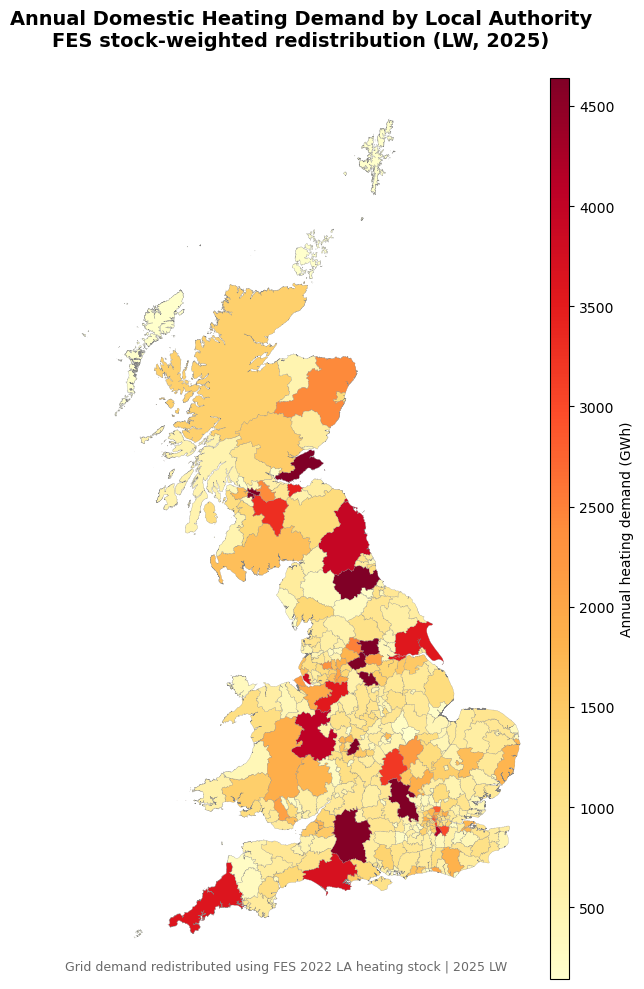

Saved figure: data\outputs\LA_level_heat_profile\Figure_LA_heat_demand_2022_LW_2025.png


In [15]:
# ============================================================
# 11. Plot LA annual heat demand map
# ============================================================

if plot_map:
    fig, ax = plt.subplots(figsize=(8, 10))

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.08)

    vmin = la_map["Allocated_Heat_GWh"].quantile(0.02)
    vmax = la_map["Allocated_Heat_GWh"].quantile(0.98)

    la_map.plot(
        column="Allocated_Heat_GWh",
        cmap="YlOrRd",
        linewidth=0.15,
        edgecolor="grey",
        legend=True,
        cax=cax,
        vmin=vmin,
        vmax=vmax,
        missing_kwds={"color": "white"},
        legend_kwds={"label": "Annual heating demand (GWh)"},
        ax=ax
    )

    ax.set_title(
        f"Annual Domestic Heating Demand by Local Authority\n"
        f"FES stock-weighted redistribution ({scenario}, {future_year})",
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.text(
        0.01,
        0.01,
        f"Grid demand redistributed using FES {FES} LA heating stock | {future_year} {scenario}",
        transform=ax.transAxes,
        fontsize=9,
        color="dimgray"
    )

    ax.axis("off")
    plt.tight_layout()

    fig_path = output_dir / f"Figure_LA_heat_demand_{FES}_{scenario}_{future_year}.png"
    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()

    print("Saved figure:", fig_path)